# Wine review vintage distribution

This notebook loads the Wine Reviews CSV stored in a `datasets/` folder beside this notebook, extracts a four-digit vintage year from each review's `title`, and examines how many reviews fall in each vintage.

The Wine Reviews data documentation says that the `title` field can be parsed for vintage. A missing extracted vintage means the title did not contain a four-digit year matching the pattern used below; it does **not** necessarily mean the wine has no vintage.

In [3]:
%pip install pandas matplotlib seaborn

  Using cached pandas-3.0.6-cp313-cp313-win_amd64.whl.metadata (19 kB)
  Using cached seaborn-0.13.2-py3-none-any.whl.metadata (5.4 kB)
Using cached pandas-3.0.6-cp313-cp313-win_amd64.whl (9.6 MB)
Using cached seaborn-0.13.2-py3-none-any.whl (294 kB)

   ---------------------------------------- 0/3 [tzdata]
   ---------------------------------------- 0/3 [tzdata]
   ---------------------------------------- 0/3 [tzdata]
   ---------------------------------------- 0/3 [tzdata]
   ---------------------------------------- 0/3 [tzdata]
   ---------------------------------------- 0/3 [tzdata]
   ---------------------------------------- 0/3 [tzdata]
   ---------------------------------------- 0/3 [tzdata]
   ---------------------------------------- 0/3 [tzdata]
   ---------------------------------------- 0/3 [tzdata]
   ---------------------------------------- 0/3 [tzdata]
   ---------------------------------------- 0/3 [tzdata]
   ---------------------------------------- 0/3 [tzdata]
   ----

In [4]:
from pathlib import Path
import re

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_colwidth", 100)

In [5]:
# The notebook expects one or more CSV files here.
DATA_DIR = Path("datasets")

if not DATA_DIR.exists():
    raise FileNotFoundError(
        f"Could not find {DATA_DIR.resolve()}. Create a 'datasets' folder next to this notebook and put the CSV there."
    )

csv_files = sorted(DATA_DIR.glob("*.csv"))
if not csv_files:
    raise FileNotFoundError(f"No CSV files found in {DATA_DIR.resolve()}.")

print("CSV file(s) found:")
for file in csv_files:
    print(f"- {file}")

# If your folder contains multiple CSVs, set this explicitly, e.g.:
# DATA_FILE = DATA_DIR / 'winemag-data-130k-v2.csv'
DATA_FILE = next((f for f in csv_files if "130k-v2" in f.name.lower()), csv_files[0])
print(f"\nLoading: {DATA_FILE}")

CSV file(s) found:
- datasets\winemag-data-130k-v2.csv
- datasets\winemag-data_first150k.csv

Loading: datasets\winemag-data-130k-v2.csv


In [6]:
reviews = pd.read_csv(DATA_FILE)

# Kaggle exports often include an unnamed index column; remove it if present.
unnamed_columns = [column for column in reviews.columns if column.lower().startswith("unnamed:")]
reviews = reviews.drop(columns=unnamed_columns)

if "title" not in reviews.columns:
    raise KeyError(
        "This file does not have a 'title' column. Choose the Wine Reviews CSV that includes title information."
    )

print(f"Rows: {len(reviews):,}")
print(f"Columns: {reviews.columns.tolist()}")
reviews.head()

Rows: 129,971
Columns: ['country', 'description', 'designation', 'points', 'price', 'province', 'region_1', 'region_2', 'taster_name', 'taster_twitter_handle', 'title', 'variety', 'winery']


,country,description,designation,points,price,province,region_1,region_2,taster_name,taster_twitter_handle,title,variety,winery
0,Italy,"Aromas include tropical fruit, broom, brimstone and dried herb. The palate isn't overly expressi...",Vulkà Bianco,87,NaN,Sicily & Sardinia,Etna,NaN,Kerin O’Keefe,@kerinokeefe,Nicosia 2013 Vulkà Bianco (Etna),White Blend,Nicosia
1,Portugal,"This is ripe and fruity, a wine that is smooth while still structured. Firm tannins are filled o...",Avidagos,87,15.0,Douro,NaN,NaN,Roger Voss,@vossroger,Quinta dos Avidagos 2011 Avidagos Red (Douro),Portuguese Red,Quinta dos Avidagos
2,US,"Tart and snappy, the flavors of lime flesh and rind dominate. Some green pineapple pokes through...",NaN,87,14.0,Oregon,Willamette Valley,Willamette Valley,Paul Gregutt,@paulgwine,Rainstorm 2013 Pinot Gris (Willamette Valley),Pinot Gris,Rainstorm
3,US,"Pineapple rind, lemon pith and orange blossom start off the aromas. The palate is a bit more opu...",Reserve Late Harvest,87,13.0,Michigan,Lake Michigan Shore,NaN,Alexander Peartree,NaN,St. Julian 2013 Reserve Late Harvest Riesling (Lake Michigan Shore),Riesling,St. Julian
4,US,"Much like the regular bottling from 2012, this comes across as rather rough and tannic, with rus...",Vintner's Reserve Wild Child Block,87,65.0,Oregon,Willamette Valley,Willamette Valley,Paul Gregutt,@paulgwine,Sweet Cheeks 2012 Vintner's Reserve Wild Child Block Pinot Noir (Willamette Valley),Pinot Noir,Sweet Cheeks


In [7]:
# Extract the first likely wine vintage in the title.
# The bounds keep years such as 1899--2099 while avoiding numbers embedded in longer strings.
VINTAGE_PATTERN = r"(?<!\d)((?:18|19|20)\d{2})(?!\d)"
reviews["vintage"] = pd.to_numeric(
    reviews["title"].astype("string").str.extract(VINTAGE_PATTERN, expand=False),
    errors="coerce",
).astype("Int64")

reviews[["title", "vintage"]].head(10)

,title,vintage
0,Nicosia 2013 Vulkà Bianco (Etna),2013
1,Quinta dos Avidagos 2011 Avidagos Red (Douro),2011
2,Rainstorm 2013 Pinot Gris (Willamette Valley),2013
3,St. Julian 2013 Reserve Late Harvest Riesling (Lake Michigan Shore),2013
4,Sweet Cheeks 2012 Vintner's Reserve Wild Child Block Pinot Noir (Willamette Valley),2012
5,Tandem 2011 Ars In Vitro Tempranillo-Merlot (Navarra),2011
6,Terre di Giurfo 2013 Belsito Frappato (Vittoria),2013
7,Trimbach 2012 Gewurztraminer (Alsace),2012
8,Heinz Eifel 2013 Shine Gewürztraminer (Rheinhessen),2013
9,Jean-Baptiste Adam 2012 Les Natures Pinot Gris (Alsace),2012


In [8]:
vintage_counts = (
    reviews.dropna(subset=["vintage"])
    .groupby("vintage")
    .size()
    .rename("review_count")
    .sort_index()
)

missing_vintages = reviews["vintage"].isna().sum()
print(f"Reviews with an extracted vintage: {len(reviews) - missing_vintages:,} ({(1 - missing_vintages / len(reviews)):.1%})")
print(f"Reviews without an extracted vintage: {missing_vintages:,} ({(missing_vintages / len(reviews)):.1%})")
print(f"Vintage range: {vintage_counts.index.min()}--{vintage_counts.index.max()}")

vintage_counts.to_frame()

Reviews with an extracted vintage: 125,360 (96.5%)
Reviews without an extracted vintage: 4,611 (3.5%)
Vintage range: 1821--2017


,review_count
vintage,
1821,4
1827,2
1845,3
1847,1
1848,6
...,...
2013,15859
2014,15573
2015,10042


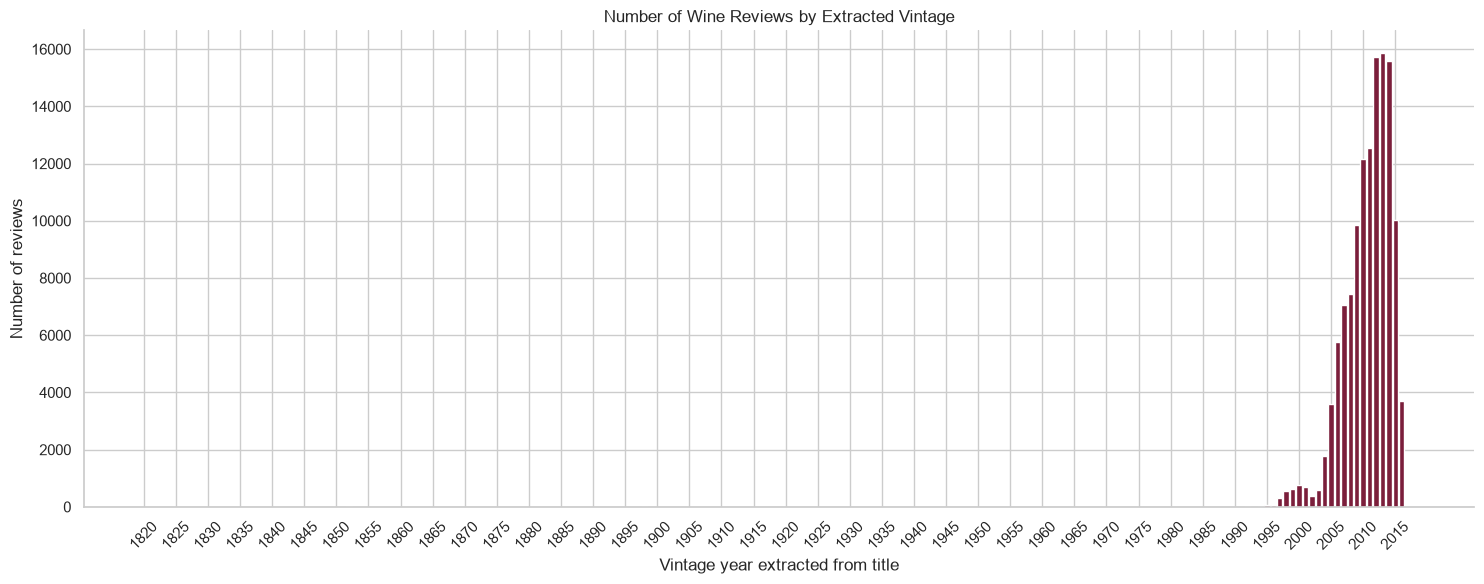

In [9]:
# The full distribution. The x-axis is shown in 5-year increments to stay readable.
fig, ax = plt.subplots(figsize=(15, 6))
ax.bar(vintage_counts.index.astype(int), vintage_counts.values, color="#7b1e3b", width=0.85)
ax.set(
    title="Number of Wine Reviews by Extracted Vintage",
    xlabel="Vintage year extracted from title",
    ylabel="Number of reviews",
)
start_tick = (int(vintage_counts.index.min()) // 5) * 5
ax.set_xticks(range(start_tick, int(vintage_counts.index.max()) + 1, 5))
ax.tick_params(axis="x", rotation=45)
sns.despine()
plt.tight_layout()
plt.show()

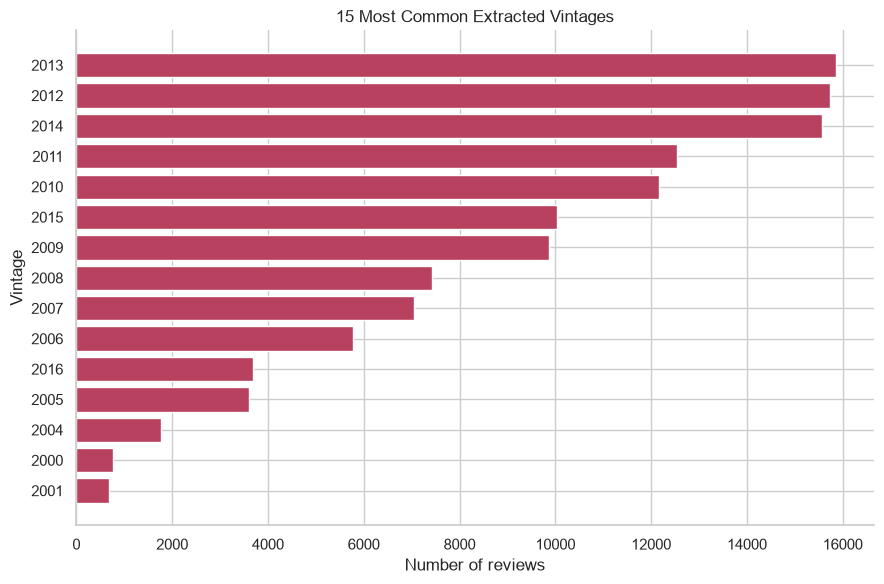

,review_count
vintage,
2013,15859
2012,15729
2014,15573
2011,12532
2010,12153
2015,10042
2009,9866
2008,7428
2007,7047


In [10]:
# A compact view of the vintages that occur most often.
top_vintages = vintage_counts.sort_values(ascending=False).head(15).sort_values()

fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(top_vintages.index.astype(str), top_vintages.values, color="#b7415e")
ax.set(
    title="15 Most Common Extracted Vintages",
    xlabel="Number of reviews",
    ylabel="Vintage",
)
sns.despine()
plt.tight_layout()
plt.show()

top_vintages.sort_values(ascending=False).to_frame("review_count")

In [11]:
# Count reviews where no vintage was extracted from the title
na_vintage_count = reviews["vintage"].isna().sum()

print(f"Reviews with NA vintage: {na_vintage_count:,}")
print(f"Percent of all reviews: {na_vintage_count / len(reviews):.2%}")

# Show example rows whose title did not produce a vintage
reviews.loc[
    reviews["vintage"].isna(),
    ["title", "country", "province", "variety", "points", "price"]
].head(20)

Reviews with NA vintage: 4,611
Percent of all reviews: 3.55%


,title,country,province,variety,points,price
63,Roland Champion NV Brut Rosé (Champagne),France,Champagne,Champagne Blend,86,58.0
69,Collet NV Brut Rosé (Champagne),France,Champagne,Champagne Blend,86,55.0
237,Consorzio Vini Tipici di San Marino NV Moscato (San Marino),Italy,Central Italy,Moscato,85,18.0
315,Bellussi NV Extra Dry (Prosecco di Valdobbiadene),Italy,Veneto,Prosecco,86,15.0
326,Marsuret NV Extra Dry (Prosecco di Valdobbiadene),Italy,Veneto,Prosecco,86,15.0
332,Sommariva NV Palazzo Rosso Brut (Prosecco di Conegliano),Italy,Veneto,Prosecco,86,19.0
333,Spagnol NV Col del Sas Extra Dry (Prosecco di Valdobbiadene),Italy,Veneto,Prosecco,86,18.0
334,Jacquart NV Mosaïque Rosé Brut (Champagne),France,Champagne,Champagne Blend,86,42.0
342,Bellisco NV Sparkling (Cava),Spain,Catalonia,Sparkling Blend,82,11.0
345,Chambers Rosewood Vineyards NV Rare Muscat (Rutherglen),Australia,Victoria,Muscat,100,350.0


## Interpretation reminders

- This is the distribution of **reviews in this scraped dataset**, not a distribution of all wine production or quality.
- Older vintages can be underrepresented because fewer bottles remain available for review and because the dataset was collected around 2017.
- Review titles without a recognizable four-digit year are excluded from the by-vintage charts. Inspect those rows before deciding whether to drop them in later analysis.